In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


ma trận hiệp phương sai: 
[[ 115.7  -120.55]
 [-120.55  138.7 ]]


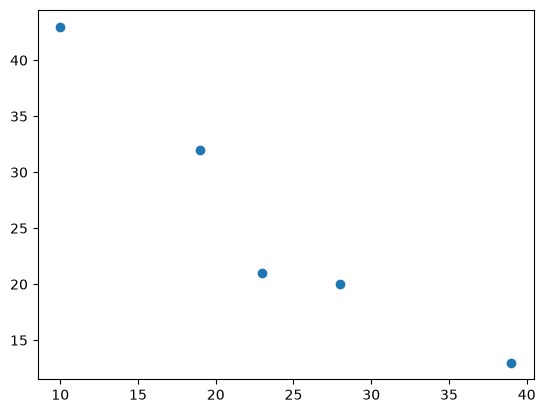

In [6]:
x = np.array([10,39,19,23,28])
y = np.array([43,13,32,21,20])

print('ma trận hiệp phương sai: ')
cov_xy = np.cov(x,y)
print(cov_xy)

plt.scatter(x,y)


In [8]:
#dữ  liệu 3 chiều:
x3 = np.array([[1,-1,4],[2,1,3],[1,3,-1]])
print('ma trận hiệp phương sai: ')
cov_x3 = np.cov(x3)
print(x3)

print('ma trận tương quan: ')
print(np.corrcoef(x3))


ma trận hiệp phương sai: 
[[ 1 -1  4]
 [ 2  1  3]
 [ 1  3 -1]]
ma trận tương quan: 
[[ 1.          0.99339927 -0.99339927]
 [ 0.99339927  1.         -1.        ]
 [-0.99339927 -1.          1.        ]]


### Bài 2


In [12]:
data = np.array([
    [2.5, 2.4], [0.5, 0.7], [2.2, 2.9], [1.9, 2.2], [3.1, 3.0],
    [2.3, 2.7], [2.0, 1.6], [1.0, 1.1], [1.5, 1.6], [1.1, 0.9],
])
df = pd.DataFrame(data, columns=('x','y'))
df

,x,y
0,2.5,2.4
1,0.5,0.7
2,2.2,2.9
3,1.9,2.2
4,3.1,3.0
5,2.3,2.7
6,2.0,1.6
7,1.0,1.1
8,1.5,1.6
9,1.1,0.9


In [13]:
mean = data.mean()
print('giá trị trung bình: ',mean)

data_adj = data - mean
print(' sau khi chuẩn hóa: ')
print(data_adj)

giá trị trung bình:  1.8599999999999999
 sau khi chuẩn hóa: 
[[ 0.64  0.54]
 [-1.36 -1.16]
 [ 0.34  1.04]
 [ 0.04  0.34]
 [ 1.24  1.14]
 [ 0.44  0.84]
 [ 0.14 -0.26]
 [-0.86 -0.76]
 [-0.36 -0.26]
 [-0.76 -0.96]]


In [21]:
# ma trận hiệp phương sai
cov = np.cov(data_adj,rowvar=False)
print('ma trận hiệp phương sai: ')
print(cov)
#tính giá trị riêng và vector riêng
giaTriRieng , vectorRieng = np.linalg.eigh(cov)
print('giá trị riêng: ',giaTriRieng)
print('vector riêng: \n',vectorRieng)
print('cột có giá trị riêng cao nhất: ',giaTriRieng.argmax()+1)


ma trận hiệp phương sai: 
[[0.61655556 0.61544444]
 [0.61544444 0.71655556]]
giá trị riêng:  [0.0490834  1.28402771]
vector riêng: 
 [[-0.73517866  0.6778734 ]
 [ 0.6778734   0.73517866]]
cột có giá trị riêng cao nhất:  2


In [18]:
new_data = vectorRieng.T @ data_adj.T
print('diwx liệu mới')
print(new_data)

diwx liệu mới
[[-0.1044627   0.21350983  0.45502759  0.20106981 -0.13884586  0.24593505
  -0.2791721   0.11706986  0.08841723 -0.09202268]
 [ 0.83083545 -1.77471506  0.99506276  0.27707568  1.67866668  0.91581437
  -0.09624417 -1.1417069  -0.43518087 -1.22095529]]


In [27]:
v_main = vectorRieng[:,1].reshape(1,2)
data_1d = v_main @ data_adj.T
print('dữ liệu 1 chiều: \n', data_1d)
print('phương sai giữ lại: ', giaTriRieng[1]/giaTriRieng.sum())

dữ liệu 1 chiều: 
 [[ 0.83083545 -1.77471506  0.99506276  0.27707568  1.67866668  0.91581437
  -0.09624417 -1.1417069  -0.43518087 -1.22095529]]
phương sai giữ lại:  0.963181314348646


In [31]:
data_back = (v_main.T @ data_1d).T + mean
pd.DataFrame(np.hstack([data,data_back]),columns=['x','y','x_rec','y_rec'])

,x,y,x_rec,y_rec
0,2.5,2.4,2.423201,2.470812
1,0.5,0.7,0.656968,0.555267
2,2.2,2.9,2.534527,2.591549
3,1.9,2.2,2.047822,2.063700
4,3.1,3.0,2.997923,3.094120
5,2.3,2.7,2.480806,2.533287
6,2.0,1.6,1.794759,1.789243
7,1.0,1.1,1.086067,1.020641
8,1.5,1.6,1.565002,1.540064
9,1.1,0.9,1.032347,0.962380


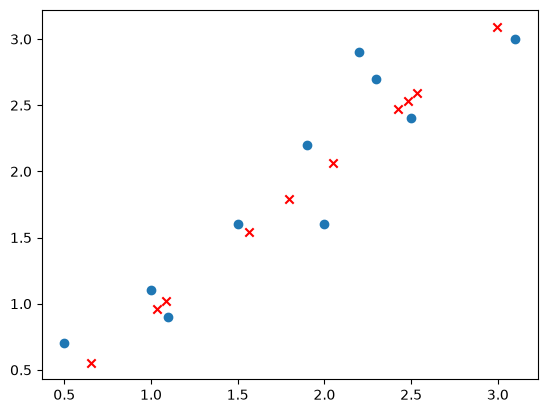

In [37]:
plt.scatter(data[:,0],data[:,1],label = 'gốc')
plt.scatter(data_back[:,0],data_back[:,1],c = 'red', marker='x',label = 'PCA')
plt.show()

## bài 3

In [35]:
from sklearn.decomposition import PCA

pca_2 = PCA(n_components=2)
pca_2.fit(data)
print('mean', pca_2.mean_)
print('components (mỗi hàng là 1 vector riêng)', pca_2.components_)
print('giá trị riêng: ',pca_2.explained_variance_)

#giảm chiều còn 1 chiều:
pca_1 = PCA(n_components= 1)
data_pca1 = pca_1.fit_transform(data)
data_pca1_back = pca_1.inverse_transform(data_pca1)

print('dữ liệu 1 chiều: \n', data_pca1)

print('đối chiếu với dữ liệu ban đầu và dữ liệu thủ công')
pd.DataFrame(np.hstack([data,data_back,data_pca1_back]),columns=['x','y','x_rec','y_rec','x_rec1','y_rec1'])

mean [1.81 1.91]
components (mỗi hàng là 1 vector riêng) [[ 0.6778734   0.73517866]
 [ 0.73517866 -0.6778734 ]]
giá trị riêng:  [1.28402771 0.0490834 ]
dữ liệu 1 chiều: 
 [[ 0.82797019]
 [-1.77758033]
 [ 0.99219749]
 [ 0.27421042]
 [ 1.67580142]
 [ 0.9129491 ]
 [-0.09910944]
 [-1.14457216]
 [-0.43804614]
 [-1.22382056]]
đối chiếu với dữ liệu ban đầu và dữ liệu thủ công


,x,y,x_rec,y_rec,x_rec1,y_rec1
0,2.5,2.4,2.423201,2.470812,2.371259,2.518706
1,0.5,0.7,0.656968,0.555267,0.605026,0.603161
2,2.2,2.9,2.534527,2.591549,2.482584,2.639442
3,1.9,2.2,2.047822,2.063700,1.995880,2.111594
4,3.1,3.0,2.997923,3.094120,2.945981,3.142013
5,2.3,2.7,2.480806,2.533287,2.428864,2.581181
6,2.0,1.6,1.794759,1.789243,1.742816,1.837137
7,1.0,1.1,1.086067,1.020641,1.034125,1.068535
8,1.5,1.6,1.565002,1.540064,1.513060,1.587958
9,1.1,0.9,1.032347,0.962380,0.980405,1.010273


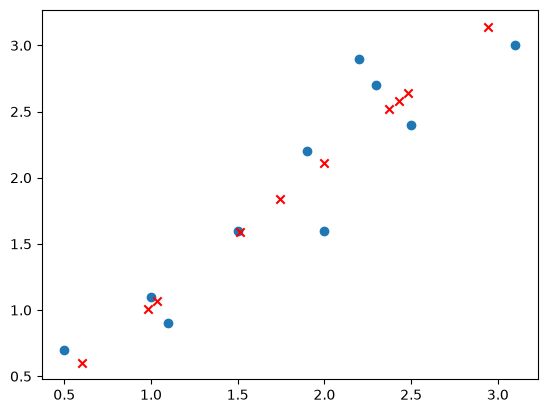

In [36]:
plt.scatter(data[:,0],data[:,1],label = 'gốc')
plt.scatter(data_pca1_back[:,0],data_pca1_back[:,1],c = 'red', marker='x',label = 'PCA')
plt.show()

## bài 5

In [38]:
from skimage.color import rgb2gray
from skimage import data
from scipy.linalg import svd



In [39]:
#5.1
A = np.array([[3,2,2],[2,3,-2]])
A

array([[ 3,  2,  2],
       [ 2,  3, -2]])

In [40]:
U,s,VT = svd(A)


In [43]:
#in các thành phần
m, n = A.shape
sigma = np.zeros((m,n))
sigma[:min(m,n), :min(m,n)] = np.diag(s)

print('U : \n',U)
print('Giá trị kì dị : \n',s)
print('tổng m x n : \n',sigma)
print('VT : \n',VT)

U : 
 [[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]
Giá trị kì dị : 
 [5. 3.]
tổng m x n : 
 [[5. 0. 0.]
 [0. 3. 0.]]
VT : 
 [[ 7.07106781e-01  7.07106781e-01  3.67439059e-16]
 [-2.35702260e-01  2.35702260e-01 -9.42809042e-01]
 [-6.66666667e-01  6.66666667e-01  3.33333333e-01]]


In [47]:
# Pseudo-inverse
sigma_p = np.zeros((n,m))
sigma_p[:len(s),:len(s)] = np.diag(1/s)

A_pinv = VT.T @ sigma_p @ U.T
print('Pseudo-inverse: \n',A_pinv)
print('trùng: ',np.allclose(A_pinv, np.linalg.pinv(A)))
print('A . A+: ',A@A_pinv)

Pseudo-inverse: 
 [[ 0.15555556  0.04444444]
 [ 0.04444444  0.15555556]
 [ 0.22222222 -0.22222222]]
trùng:  True
A . A+:  [[ 1.00000000e+00 -5.55111512e-17]
 [-2.77555756e-16  1.00000000e+00]]


kích thước:  (300, 451, 3)
kích thước ảnh xám:  (300, 451)


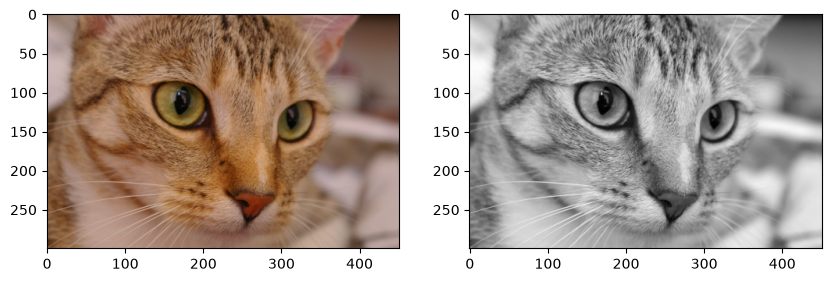

In [55]:
img = data.chelsea()
print('kích thước: ',img.shape)
img_gray = rgb2gray(img)
print('kích thước ảnh xám: ',img_gray.shape)
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.subplot(1,2,2)
plt.imshow(img_gray,cmap='gray')
plt.show()

In [61]:
U_i, s_i , VT_i = svd(img_gray,full_matrices=False)
print('U: ',U_i.shape)
print('s_i: ',U_i.shape)
print('VT_i: ',U_i.shape)
def compare(k):
    #chỉ giữ giá trị kì dị lớn nhất:
    return U_i[:,:k] @ np.diag(s_i[:k]) @ VT_i[:k,:]
h, w = img_gray.shape
ks = [1,5,20,50,100,200]
results = []
for k in ks:
    rec = compare(k)
    err = np.linalg.norm(img_gray - rec)/np.linalg.norm(img)
    ratio = (k * (h+w+1))/(h*w)
    enegy = (s_i[:k] **2).sum()/(s_i **2).sum()
    results.append((k,rec,err,ratio,enegy))

pd.DataFrame([(k,e,r,en) for k,_,e,r,en in results], columns=('k','sai số tương đối','dung lượng so với gốc', 'năng lượng giữ lại'))

U:  (300, 300)
s_i:  (300, 300)
VT_i:  (300, 300)


,k,sai số tương đối,dung lượng so với gốc,năng lượng giữ lại
0,1,0.000537,0.005558,0.942709
1,5,0.000340,0.027790,0.977042
2,20,0.000170,0.111160,0.994250
3,50,0.000095,0.277901,0.998216
4,100,0.000049,0.555802,0.999527
5,200,0.000013,1.111604,0.999968


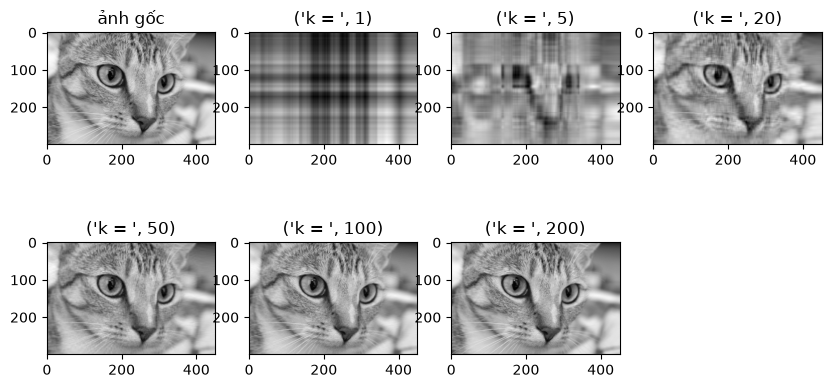

In [77]:
#kết quả:
plt.figure(figsize=(10,5))
plt.subplot(2,4,1)
plt.imshow(img_gray,cmap= 'gray')
plt.title('ảnh gốc')

i = 2
for k,rec,err,r,en in results:
    plt.subplot(2,4,i)
    plt.imshow(np.clip(rec,0,1),cmap = 'gray')
    plt.title(( "k = ",k))
    i += 1

plt.show()
